# Posterior sampling of rupture rates: full workflow

This notebook runs the whole workflow from the raw `cru_A.txt` / `cru_D.txt` files to the summary tables:

1. self-tests of the sampler against exact answers;
2. loading, cleaning and characterising the problem (`preliminaries.py`), with the MFD bins' uncertainty level set by `MFD_UNCERTAINTY`;
3. replicate runs (`gibbs.py`) under one chosen prior (`PRIOR_KIND`) and the plain likelihood: by default spike-and-slab (each rupture switched off, or on with a log-uniform rate below a soft top at its bin's target rate R_j, and the fraction on in each bin estimated), or `'theta'`, per-bin log-uniform boxes with depths chosen so that the prior exerts no pressure on the bin totals;
4. convergence checks (R̂ against its noise baseline, effective sample sizes, the hyperparameters, agreement between replicates) and how well each row block is fitted;
5. the results (exceedance probabilities per rupture, subsection and bin totals), exported as CSV files keyed by the original rupture and row numbers.

**Setup.** Put this notebook in the folder with the scripts (`cru_common.py`, `preliminaries.py`, `block_fit.py`, `gibbs.py`, `summarize_runs.py`, `select_draws.py`, `plot_rate_magnitude.py`, `plot_slip_rates.py`, `plot_paleo_rates.py`, `compare_runs.py`, `compare_priors.py`). The two data files and the outputs can live in folders of their own: set `DATA_DIR` (read only) and `RUN_DIR` (everything the workflow writes: the cleaned problem, the runs, figures and CSV tables) in the configuration cell. Relative paths are taken from this notebook's folder, and both default to it. Within `RUN_DIR`, the cleaned problem and diagnostics stay at the top, and each prior's runs, tables and figures go into a subfolder named after it (`spikeslab/` or `theta/`, each with a copy of the configuration), so runs with different priors never overwrite each other; to keep two settings of the same prior (a second floor, say), give the second its own `RUN_DIR`. A different `MFD_UNCERTAINTY` or `SLIP_SECTIONS` changes the cleaned problem, so it too needs its own `RUN_DIR`. Everything the notebook prints (its own messages, the scripts' output, warnings, and any error with its traceback) is also written to a log in the prior's subfolder, `workflow_log_<date>-<time>.txt`, a new one each time the configuration cell runs; in Jupyter the log also records when each cell started and how long it took, and which figures were shown. Requirements: numpy, scipy, pandas, matplotlib, and a C compiler (`xcode-select --install` on macOS) for the Gibbs kernel. Edit the configuration cell, then run all cells in order. `PRESET = 'quick'` takes minutes; `'conservative'` uses the production settings; `'very_conservative'` (16 chains, 3 replicates; on an M2's four performance cores about 4 hours for θ, measured, and an estimated 3 for spike-and-slab) aims at 10,000 effective draws per rupture, so that exceedance probabilities near 0.02 carry under 10% Monte Carlo error. See `REPORT.md` for the reasoning behind every choice.

In [1]:
# Configuration: edit this cell, then run all cells in order.
import os, sys, json, time, subprocess, csv
import numpy as np

DATA_DIR = '~/inversions/NZSHM22_Matrices-19k/'                             # folder with the input data files (read only); relative paths are taken
                                           # from this notebook's folder, which also holds the scripts
RUN_DIR = '~/inversions/NZSHM22_Matrices-19k/spikeslab_vcon_mfdunc1/'                              # folder for everything the workflow writes (created if missing)
A_FILE, D_FILE = 'cru_A.txt', 'cru_D.txt'  # input file names, inside DATA_DIR
BLOCKS = None                              # row groups by original row numbers, e.g. 'S=0-387,MFD=695-713,P=714-753'.
                                           # None detects the slip-rate rows (the leading rows, up to the first zero-forcing
                                           # penalty row) and the magnitude-bin rows; any group named is checked against them
SLIP_BLOCK, BIN_BLOCK = 'S', 'MFD'         # blocks used for subsection and magnitude-bin summaries
SLIP_SECTIONS = 'auto'                     # slip-rate measurements: 'auto' (default): each run of subsections holding
                                           # copies of one fault section's slip rate is one measurement (its k rows are
                                           # divided by sqrt(k)); rows unlike their neighbours (a geodetic model, say) are
                                           # unchanged; 'none': every subsection its own measurement (the inputs as given;
                                           # a sensitivity test, in its own RUN_DIR); or a file in DATA_DIR of
                                           # 'original_row section' lines (e.g. the rupture set's subsection-to-section map)
MFD_UNCERTAINTY = 1                      # the MFD bins' uncertainty level, applied at cleaning; their bin-to-bin
                                           # shape (the power, 0.25 in the NZSHM22 inputs) stays as cru_A/cru_D give it.
                                           # 'as-given' (default): the inputs' uncertainties (10% at M7.0-7.1, their design
                                           # value), each bin its own measurement; 'two-measurements': the bins are a
                                           # projection of two measurements, the rate of M>=5 and the b-value, so together
                                           # they count as two measurements, not one per bin: every bin's uncertainty is
                                           # multiplied by sqrt(bins / 2) (3 for 18 bins: 30% at M7.0-7.1); a number: the
                                           # M7.0-7.1 bin's relative uncertainty, one sd (0.1 reproduces the inputs). A
                                           # different setting changes the cleaned problem, so it needs its own RUN_DIR

PRESET = 'very_conservative'                    # 'quick' to try the workflow; 'conservative' for production;
                                           # 'very_conservative' for the most precise results (hours)
PRIOR_KIND = 'spikeslab'                   # 'spikeslab' (default): each rupture off (rate 0) or on, log-uniform from
                                           # 10^FLOOR up to the top at its bin's target rate R_j (see BOX_TOP); the fraction
                                           # on in each bin is estimated, so no floor or depth sets the sparsity;
                                           # 'theta': per-bin log-uniform boxes below R_j, depths n_j / (THETA ln 10), which
                                           # put no pressure on the bin totals at THETA = 1 (the same answer by another
                                           # route; slower mixing); 'binbox': the earlier default, kept for comparison only
BOX_TOP = 'soft'                           # the top of each bin's rate range: 'soft' (default): at R_j with a Gaussian
                                           # shoulder in log rate, sd = the bin's own relative uncertainty; 'hard': hard top
                                           # at R_j; a number F: hard top at F x R_j
THETA = 1.0                                # 'theta' prior: per-bin depths n_j / (THETA ln 10) decades, i.e. THETA ruptures per
                                           # unit of ln(rate) a priori; THETA = 1 puts no pressure on the bin totals
BOX_DEPTH = None                           # 'binbox' only: None ends its boxes at 10^FLOOR, a number N decades below R_j
FLOOR = -10                                # log10 rate below which rates are negligible (1e-10): spike-and-slab's slab
                                           # floor (the lower end of its 'on' range; also binbox's floor, whose earlier
                                           # default was -12), and the cutoff
                                           # below which rates count as equal in the convergence checks, the summary
                                           # figure and the preliminaries' collective-scale check (REPORT.md, "Floors and
                                           # cutoff")
USE_SWAPS = True                           # exact swap moves between near-duplicate ruptures (same bin)
OUTPUT_DRAWS = True                        # write the draws files? They dominate disk use. Either way each run writes its
                                           # running summaries (<run>_stream.npz), from which the rate vectors are always
                                           # computed; without draws the checks, tables and summary figure also come
                                           # from them
REPRESENTATIVES = 50                       # representative draws for hazard: each run keeps 1,000 whole draws (gibbs.py
                                           # --keep-draws) and select_draws.py picks this many weighted representatives,
                                           # written as columns rep_01... of rate_vectors.csv; 0 turns both off
THREADS = 4                                # the M2's performance cores
SA_STARTS = None                           # optional .npy (chains x ruptures) of starting models, e.g. simulated-annealing
                                           # solutions; any nonnegative models will do
RUN_SELFTESTS = False                       # 5-10 minutes; worth doing once on each machine

# Run lengths per prior. A minority of ruptures switch on and off slowly under spikeslab and theta, so their runs are
# long; for spikeslab, hyper_every sets how often (in sweeps) the fraction on in each bin is updated (cheap).
PRESETS = {
    'quick':        {'spikeslab':    dict(chains=4, sweeps=2400, burn=400, thin=8, hyper_every=1, replicates=2),
                     'theta':        dict(chains=4, sweeps=2400, burn=400, thin=8, replicates=2),
                     'binbox':       dict(chains=4, sweeps=1200, burn=200, thin=8, replicates=2)},
    'conservative': {'spikeslab':    dict(chains=8, sweeps=20000, burn=4000, thin=16, hyper_every=1, replicates=2),
                     'theta':        dict(chains=8, sweeps=20000, burn=4000, thin=16, replicates=2),
                     'binbox':       dict(chains=8, sweeps=10000, burn=2000, thin=8, replicates=2)},
    # at least 10,000 effective draws for 95% of ruptures, so exceedance probabilities near 0.02 carry under 10%
    # Monte Carlo error; on an M2's 4 performance cores about 4 hours for theta's replicates (measured), and an
    # estimated 3 for spikeslab's
    'very_conservative': {'spikeslab':    dict(chains=16, sweeps=100000, burn=20000, thin=16, hyper_every=1, replicates=3),
                     'theta':        dict(chains=16, sweeps=100000, burn=20000, thin=16, replicates=3),
                     'binbox':       dict(chains=16, sweeps=40000, burn=8000, thin=16, replicates=3)},
}
if PRIOR_KIND not in ('spikeslab', 'theta', 'binbox'):
    raise ValueError(f"PRIOR_KIND = {PRIOR_KIND!r}: use 'spikeslab', 'theta' or 'binbox' (the single log-boxcar is retired)")
P = dict(PRESETS[PRESET][PRIOR_KIND])
if not (MFD_UNCERTAINTY in ('as-given', 'two-measurements') or (isinstance(MFD_UNCERTAINTY, (int, float))
                                                                   and not isinstance(MFD_UNCERTAINTY, bool) and 0 < MFD_UNCERTAINTY <= 2)):
    raise ValueError(f"MFD_UNCERTAINTY = {MFD_UNCERTAINTY!r}: use 'as-given', 'two-measurements' or the M7.0-7.1 bin's "
                     'relative uncertainty as a fraction (0.3 for 30%)')
if '_NOTEBOOK_DIR' not in globals():       # this notebook's folder, remembered so this cell can be re-run after chdir
    _NOTEBOOK_DIR = os.path.abspath('.')
CODE_DIR = _NOTEBOOK_DIR                   # the scripts sit next to this notebook
_resolve = lambda p: os.path.normpath(os.path.join(_NOTEBOOK_DIR, os.path.expanduser(str(p))))
DATA_DIR, RUN_DIR = _resolve(DATA_DIR), _resolve(RUN_DIR)
for _f in ('gibbs.py', 'cru_common.py', 'preliminaries.py', 'block_fit.py', 'summarize_runs.py', 'select_draws.py',
           'plot_rate_magnitude.py', 'plot_slip_rates.py', 'plot_paleo_rates.py'):
    if not os.path.exists(os.path.join(CODE_DIR, _f)):
        raise FileNotFoundError(f'{_f} is not next to this notebook ({CODE_DIR})')
for _f in (A_FILE, D_FILE) + (() if SLIP_SECTIONS in ('auto', 'none') else (SLIP_SECTIONS,)):
    if not os.path.exists(os.path.join(DATA_DIR, _f)):
        raise FileNotFoundError(f'{_f} is not in DATA_DIR ({DATA_DIR})')
os.makedirs(RUN_DIR, exist_ok=True)
os.chdir(RUN_DIR)                          # every output lands in RUN_DIR
sys.path.insert(0, CODE_DIR)
from cru_common import start_log, log_only # from here on, everything printed is also written to a log in the prior's folder
LOG_FILE = start_log(os.path.join(RUN_DIR, PRIOR_KIND, time.strftime('workflow_log_%Y%m%d-%H%M%S.txt')),
                     header=f"cru_workflow log, started {time.strftime('%Y-%m-%d %H:%M:%S')}")
print('code:', CODE_DIR)
print('data:', DATA_DIR)
print('runs:', RUN_DIR)
print('log: ', LOG_FILE)
print('settings:', P)

code: /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow
data: /Users/rollins/inversions/NZSHM22_Matrices-19k
runs: /Users/rollins/inversions/NZSHM22_Matrices-19k/spikeslab_vcon_mfdunc1
log:  /Users/rollins/inversions/NZSHM22_Matrices-19k/spikeslab_vcon_mfdunc1/spikeslab/workflow_log_20261021-145237.txt
settings: {'chains': 16, 'sweeps': 100000, 'burn': 20000, 'thin': 16, 'hyper_every': 1, 'replicates': 3}


In [2]:
def sh(*args):
    """Run one of the workflow scripts with this Python, streaming its output; stop on failure."""
    if str(args[0]).endswith('.py') and not os.path.isabs(str(args[0])):
        args = (os.path.join(CODE_DIR, args[0]),) + tuple(args[1:])      # scripts live in CODE_DIR
    cmd = [sys.executable] + [str(a) for a in args]
    print('$', ' '.join(cmd[1:]), flush=True)
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end='', flush=True)
    if p.wait() != 0:
        raise RuntimeError('command failed: ' + ' '.join(cmd[1:]))


def show(path):
    """Display a figure inline in Jupyter; elsewhere, say where it is."""
    try:
        from IPython.display import Image, display
        display(Image(filename=path))
        log_only(f'figure: {path}')
    except ImportError:
        print('figure:', path)


def table(rows):
    """Print a list of dicts as an aligned table."""
    fmt = lambda v: f'{v:.4g}' if isinstance(v, float) else str(v)
    keys = list(rows[0])
    width = {k: max([len(k)] + [len(fmt(r[k])) for r in rows]) for k in keys}
    print('  '.join(k.rjust(width[k]) for k in keys))
    for r in rows:
        print('  '.join(fmt(r[k]).rjust(width[k]) for k in keys))


CONFIG = dict(preset=PRESET, prior=PRIOR_KIND, box_depth=BOX_DEPTH, box_top=BOX_TOP, theta=THETA, code_dir=CODE_DIR, data_dir=DATA_DIR,
              run_dir=RUN_DIR, settings=P, floor=FLOOR, output_draws=OUTPUT_DRAWS, representatives=REPRESENTATIVES,
              swaps=USE_SWAPS, a_file=A_FILE, d_file=D_FILE, blocks=BLOCKS, slip_sections=SLIP_SECTIONS,
              mfd_uncertainty=MFD_UNCERTAINTY,
              slip_block=SLIP_BLOCK, bin_block=BIN_BLOCK, threads=THREADS, sa_starts=SA_STARTS, run_selftests=RUN_SELFTESTS,
              log_file=LOG_FILE, started=time.strftime('%Y-%m-%d %H:%M'))
json.dump(CONFIG, open('workflow_config.json', 'w'), indent=1)
log_only('configuration: ' + json.dumps(CONFIG, default=str))


def has_draws(name):
    return os.path.exists(name + '_samples.npy')


from cru_common import load_stream, stream_rhat, stream_ess, stream_quantiles   # readers of the running summaries


RATE_QS = (0.02275, 0.15865, 0.5, 0.84135, 0.97725)    # the -2, -1, 0, +1, +2 sigma points of a Gaussian


def hist_quantiles(h, lo, w, qs):
    """Quantiles per column of a log-rate histogram (bin 0: rates below 10^lo, reported as 0), interpolated within bins."""
    h = h.astype(np.float64)
    tot = h.sum(0)
    c = np.cumsum(h, 0) / tot
    cols = np.arange(h.shape[1])
    out = []
    for q in qs:
        k = np.argmax(c >= q, axis=0)
        prev = np.where(k > 0, c[np.maximum(k - 1, 0), cols], 0.0)
        frac = np.clip((q - prev) / np.maximum(h[k, cols] / tot, 1e-300), 0, 1)
        out.append(np.where(k == 0, 0.0, 10.0 ** (lo + (k - 1 + frac) * w)))
    return out


def hist_mode(h, lo, w, smooth=0.05):
    """Mode of each rate: 0 if a rate below 10^lo (including exactly 0) has probability at least 0.5; otherwise the peak
    of the log-rate density above 10^lo, smoothed by a Gaussian of sd `smooth` decades."""
    from scipy.ndimage import convolve1d
    H = h[1:].astype(np.float64)
    sdb = smooth / w
    k = np.arange(-int(np.ceil(4 * sdb)), int(np.ceil(4 * sdb)) + 1)
    ker = np.exp(-0.5 * (k / sdb) ** 2)
    j = convolve1d(H, ker / ker.sum(), axis=0, mode='constant').argmax(0)
    return np.where(h[0] >= 0.5 * h.sum(0), 0.0, 10.0 ** (lo + (j + 0.5) * w))


def run_hist(r, w=0.01, lo=-16.0):
    """Log-rate histogram, rate sum and number of draws of one run: from its running summaries, or, for runs made before
    those existed, built from its stored draws with the same binning as gibbs.py (bin width w decades)."""
    if os.path.exists(r + '_stream.npz'):
        st = load_stream(r)
        return st['hist'], st['msum'], int(st['chains']) * int(st['n_keep']), float(st['hist_lo']), float(st['hist_w'])
    S = np.load(r + '_samples.npy', mmap_mode='r')
    K, D, n = S.shape
    nb = 1 + int(round(16.5 / w))
    hist, msum = np.zeros((nb, n), np.int32), np.zeros(n)
    step = max(1, int(2e7 // (K * D)))
    for j0 in range(0, n, step):
        X = np.asarray(S[:, :, j0:j0 + step], dtype=np.float64).reshape(K * D, -1)
        c = X.shape[1]
        msum[j0:j0 + c] = X.sum(0)
        idx = np.clip(np.floor((np.log10(np.maximum(X, 1e-300)) - lo) / w).astype(np.int64) + 1, 0, nb - 1)
        hist[:, j0:j0 + c] = np.bincount((idx * c + np.arange(c)).ravel(), minlength=nb * c).reshape(nb, c)
    return hist, msum, K * D, lo, w


def rate_vectors(runs, chunk=20000):
    """Posterior mean, median, mode and 2.275/15.865/84.135/97.725% values of each rate, pooled over runs, from the
    running summaries (or stored draws, for older runs); at the original rupture positions, penalised ruptures at 0."""
    w0 = next((float(np.load(r + '_stream.npz')['hist_w']) for r in runs if os.path.exists(r + '_stream.npz')), 0.01)
    H, msum, nd, lo, w = None, 0.0, 0, None, None
    for r in runs:
        h, m, nd_r, lo_r, w_r = run_hist(r, w=w0)
        if w is not None and (w_r, lo_r) != (w, lo):
            raise ValueError('these runs have running histograms of different bin widths; pool runs made alike')
        H = h.astype(np.int32) if H is None else H + h
        msum, nd, lo, w = msum + m, nd + nd_r, lo_r, w_r
        del h
    n = H.shape[1]
    keys = ('p02.275', 'p15.865', 'median', 'p84.135', 'p97.725')
    out = {k: np.empty(n) for k in keys + ('mode',)}
    for c0 in range(0, n, chunk):
        hc = H[:, c0:c0 + chunk]
        for k, v in zip(keys, hist_quantiles(hc, lo, w, RATE_QS)):
            out[k][c0:c0 + chunk] = v
        out['mode'][c0:c0 + chunk] = hist_mode(hc, lo, w)
    out['mean'] = msum / nd
    return {k: to_original(v, prob) for k, v in out.items()}


def write_rate_vectors(runs, path):
    """Write the rate vectors to <path>.csv and <path>.npz; returns the csv path."""
    v = rate_vectors(runs)
    pen = np.ones(len(v['mean']), int)
    pen[prob['keep_cols']] = 0
    cols = ('mean', 'median', 'mode', 'p02.275', 'p15.865', 'p84.135', 'p97.725')
    with open(path + '.csv', 'w', newline='') as f:
        wr = csv.writer(f)
        wr.writerow(['rupture', 'penalised'] + list(cols))
        for i in range(len(pen)):
            wr.writerow([i, pen[i]] + [f'{v[c][i]:.6e}' for c in cols])
    np.savez(path + '.npz', penalised=pen, **{c.replace('.', '_'): v[c] for c in cols})
    return path + '.csv'


def prior_dir(kind):
    """The subfolder of RUN_DIR for one kind of prior: created if needed, with a copy of this run's configuration."""
    import shutil
    os.makedirs(kind, exist_ok=True)
    if os.path.exists('workflow_config.json'):
        shutil.copy('workflow_config.json', os.path.join(kind, 'workflow_config.json'))
    return kind

## 1. Self-tests

The Gibbs sampler is checked against exact answers: deep-tail truncated normals, two- and three-rate problems with walls, flat and exponential priors, swap and transfer moves, per-rupture box edges, the spike-and-slab prior and the retired hierarchical prior. Every line should end in `PASSED`.

In [3]:
if RUN_SELFTESTS:
    sh('gibbs.py', '--selftest')

## 2. Load, clean and characterise

The penalty rows (entries 1e20; 14 in the corrected 2e4 inputs) are removed from G and d together with the parameters they apply to (405), then all-zero rows and columns are removed. The output reports the scales, the spectrum, the resolution, near-duplicate columns and the best nonnegative fit. Cleaning also finds the row groups automatically. The slip-rate rows are the leading rows, up to the first zero-forcing penalty row (right-hand side 0, entries only on penalised ruptures), so a slip-rate row with zero slip does not end them. The magnitude-bin rows are the rows with one constant coefficient whose supports split the ruptures into disjoint groups. Groups that `BLOCKS` does not name are labelled `SLIP_BLOCK` and `BIN_BLOCK`; any group it does name must agree with the detection, or cleaning stops. Cleaning then counts each fault section's slip rate once (`SLIP_SECTIONS = 'auto'`): the inputs copy a section's slip rate, with its uncertainty, to each of its k subsections, so each run of such copies (identical targets, and identical coefficients for the ruptures they share) has its rows divided by √k. Rows unlike their neighbours, as in a geodetic slip-rate model, are unchanged; `'none'` keeps every subsection as its own measurement (a sensitivity test, in its own `RUN_DIR`), and a file of `original_row section` lines sets the sections explicitly. Cleaning reports the fit check: the χ² a draw should have if the uncertainties are right. The next cell checks the bin rows again (the per-bin priors and the bin targets rely on them) and checks that the slip-rate rows are plausible, printing a short profile: it stops on clear mislabelling and warns about anything suspicious, such as ruptures that appear in no slip-rate row.

**MFD uncertainty** (`MFD_UNCERTAINTY`, `'as-given'` by default). The magnitude bins are not independent observations: they are a projection of two, the rate of M≥5 earthquakes and the b-value, whose own uncertainties the logic tree explores through alternative inputs. The inputs give the bins relative uncertainties of 10% at M7.0–7.1, growing as R_j^−0.25 towards the rarer bins: both are design values chosen where the inputs are built, the 10% a holdover of the UCERF3 practice of weighting data types, where the slip-rate and paleo rows carry their measured uncertainties. `'as-given'` keeps them, each bin its own measurement; counted that way the 18 bins pin their total rate to ±2.8% and their slope to ±0.024 in b. `'two-measurements'` multiplies every bin's uncertainty by √(bins / 2), 3 for 18 bins, so that together they carry the information of the two measurements they come from, as each slip-rate section's copies count once: 30% at M7.0–7.1 (29–46% across the bins), and ±8.3% on the total and ±0.07 on the slope. A number sets the M7.0–7.1 bin's relative uncertainty, the other bins following (0.1 reproduces the inputs). The bin-to-bin shape always stays as the inputs give it, the bins' targets are unchanged, and the soft top's width, the bins' relative uncertainty, follows. Cleaning prints the inputs' uncertainties, the multiplier and what the bins then say about the MFD as a whole; the fit check still counts one measurement per bin. The data cannot set this level, since the bins' misfit is almost all the model's freedom; in quick runs `'two-measurements'` let the slip-rate and paleo rows raise the bins a median 8% above their targets (2% as given) and the total rate by 5%, with the other products within Monte Carlo noise (REPORT.md, "MFD uncertainty").

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/preliminaries.py --A /Users/rollins/inversions/NZSHM22_Matrices-19k/cru_A.txt --d /Users/rollins/inversions/NZSHM22_Matrices-19k/cru_D.txt --out cru_clean.npz --bins-block MFD --slip-block S --diag-floor=-10 --slip-sections auto --mfd-uncertainty 1
== raw: G 867 x 18648, nnz 1075970; d (867,); min entry 41.57, max 1e+20
== cleaning step 1: 14 penalty rows contain entries > 1e+10 (values [1.e+20]; original rows [793, 795, 796, 797, 798, 799, 801, 802, 803, 804, 805, 806, 807, 808]); they apply to 405 parameters.
   removing those rows from G and d and those parameters from G: 853 x 18243
== cleaning step 2: 407 all-zero rows and 0 all-zero columns remain
   2 rows were empty in the raw matrix (original rows [794, 800], d = [1.0, 1.0])
   405 rows (original 388-792) held only entries [10000.] on removed parameters, d = [0.]: a second zero-forcing penalty
   all-zero rows add a c

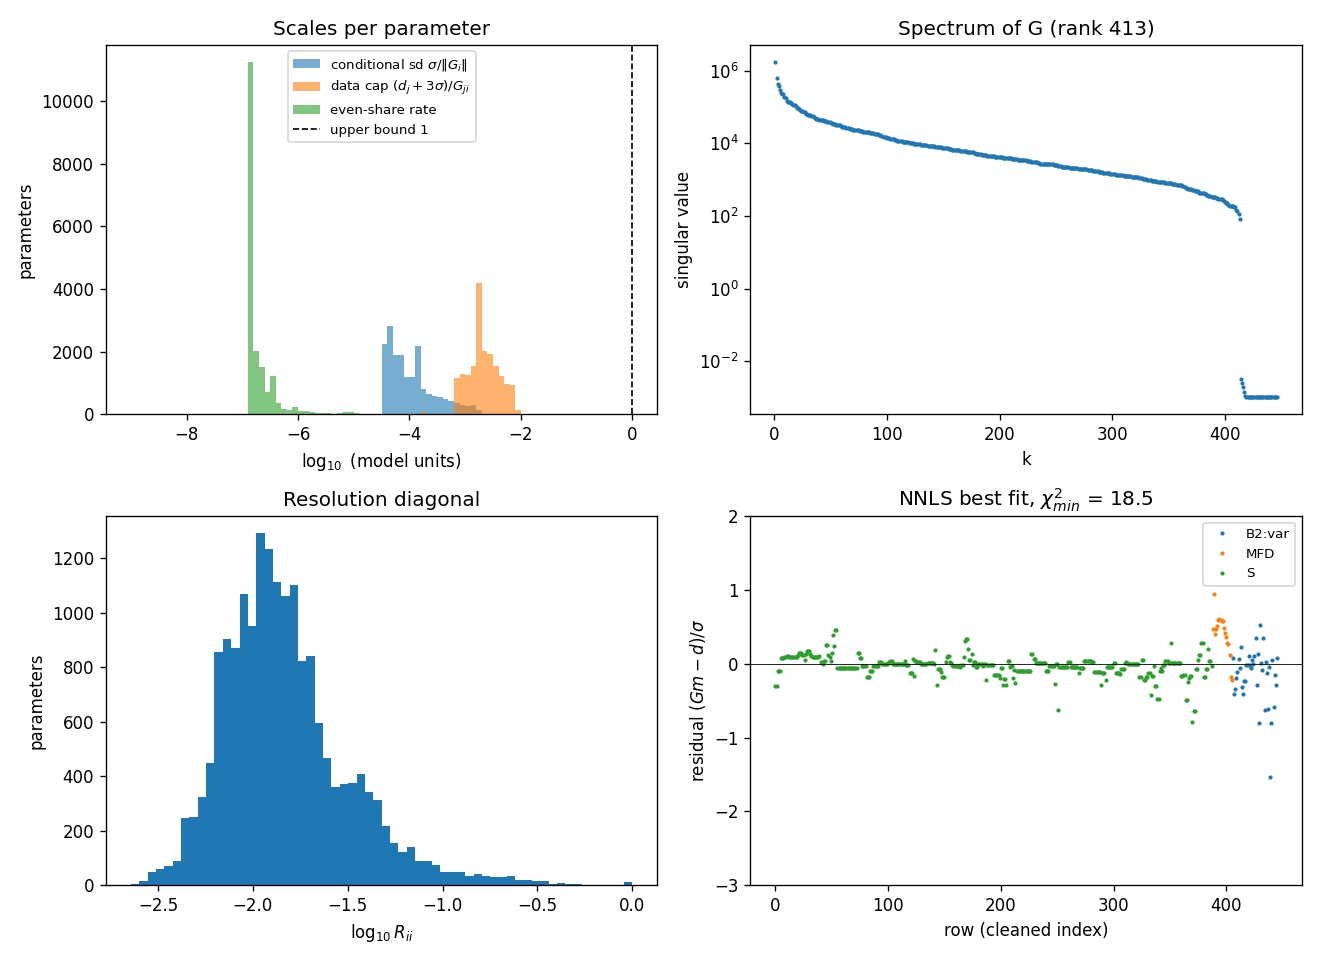

In [4]:
args = ['preliminaries.py', '--A', os.path.join(DATA_DIR, A_FILE), '--d', os.path.join(DATA_DIR, D_FILE), '--out', 'cru_clean.npz',
        '--bins-block', BIN_BLOCK, '--slip-block', SLIP_BLOCK, f'--diag-floor={FLOOR}',
        '--slip-sections', SLIP_SECTIONS if SLIP_SECTIONS in ('auto', 'none') else os.path.join(DATA_DIR, SLIP_SECTIONS),
        '--mfd-uncertainty', MFD_UNCERTAINTY]
if BLOCKS:
    args += ['--blocks', BLOCKS]
_CLEANED_BEFORE = None
if os.path.exists('cru_clean.npz'):                # the settings of a problem cleaned here before, to compare below
    from cru_common import load_problem
    _p = load_problem('cru_clean.npz')
    _CLEANED_BEFORE = (_p['slip_sections'], _p['mfd_uncertainty'])
    del _p
sh(*args)
show('prelim.png')

In [5]:
from cru_common import load_problem, split_rhat, ess, ess_many, check_bin_rows, check_slip_rows, to_original, magnitude_bins
prob = load_problem('cru_clean.npz')
prel = np.load('prelim_results.npz')
G, d = prob['G'].tocsr(), prob['d']
N, n = G.shape
N_EFF = int(np.sum(np.diff(G.indptr) > 0))
blk, bnames = prob['block'], prob['block_names']
print(f'cleaned problem: {N} rows ({N_EFF} carrying data) x {n} ruptures')
print(f'best-fit chi2 (NNLS) = {float(prel["chi2_min"]):.2f}')
print(f'single-rupture detection scale sigma/||G_i||: median {np.median(prel["s_cond"]):.1e} '
      f'(range {prel["s_cond"].min():.1e} to {prel["s_cond"].max():.1e})')
print(f'rate below which all ruptures together move any prediction by < 0.1 sigma: {0.1 / np.asarray(G.sum(1)).max():.1e}')
print('magnitude-bin rows:', check_bin_rows(prob, BIN_BLOCK))   # raises if the per-bin priors' assumptions fail
print('slip-rate rows:', check_slip_rows(prob, SLIP_BLOCK))      # raises for clear mislabelling; warns if implausible
_sec = prob['section'][prob['section'] >= 0]
if _sec.size:
    _k = np.bincount(_sec)
    print(f"slip-rate sections ({prob['slip_sections']!r}): {len(_k)} sections, {int((_k > 1).sum())} of them runs of 2-{_k.max()} copies; "
          + ('each counts as one measurement (its rows divided by sqrt(k))' if prob['slip_sections'] != 'none'
             else 'every subsection counts as its own measurement (the inputs as given)'))
_mb_rows, _, _, _mb_lo = magnitude_bins(prob, BIN_BLOCK)   # bins counted up from 6.80-6.90, as cleaning counts them
_rel = 1.0 / d[_mb_rows]
_k7 = np.flatnonzero(np.isclose(_mb_lo, 7.0))
print(f"MFD bins' uncertainties ({prob['mfd_uncertainty']!r}): "
      + (f'{100 * _rel[_k7[0]]:.1f}% at M7.0-7.1, ' if _k7.size else '') + f'{100 * _rel.min():.1f}% to {100 * _rel.max():.1f}%'
      + (f", the inputs' x {prob['mfd_scale']:.3f}" if abs(prob['mfd_scale'] - 1) > 1e-12 else ', as the inputs give them'))
_before = globals().get('_CLEANED_BEFORE')         # set by the cleaning cell: the settings of a problem cleaned here before
if _before is not None and _before != (prob['slip_sections'], prob['mfd_uncertainty']):
    _other = [k_ for k_ in ('spikeslab', 'theta', 'binbox') if k_ != PRIOR_KIND and os.path.exists(os.path.join(k_, 'main_rep0.npz'))]
    if _other:
        print(f'WARNING: RUN_DIR held a problem cleaned with SLIP_SECTIONS {_before[0]!r} and MFD_UNCERTAINTY '
              f"{_before[1]!r}; the runs in {', '.join(k_ + '/' for k_ in _other)} were made on it, not on this one. "
              'Give each setting its own RUN_DIR.')
FIT = prob['chi2_expect']                          # the fit check: chi2 of a model that matches the truth
if FIT is not None:
    print(f'fit check: if the uncertainties are right, the chi2 of a draw should be near {FIT[0]:.0f} +- {FIT[1]:.0f}')

cleaned problem: 446 rows (446 carrying data) x 18243 ruptures
best-fit chi2 (NNLS) = 18.52
single-rupture detection scale sigma/||G_i||: median 8.3e-05 (range 3.1e-05 to 2.0e-03)
rate below which all ruptures together move any prediction by < 0.1 sigma: 1.8e-09
magnitude-bin rows: 18 bin rows, each a plain sum over its ruptures; every rupture in exactly one bin; targets R_j from 0.000342 to 0.00209/yr, total 0.02143/yr
slip-rate rows: 388 rows (original 0-387) in 64 runs of identical values; each row involves a median of 852 ruptures; each rupture appears in a median of 52 rows (range 2-118)
slip-rate sections ('auto'): 68 sections, 68 of them runs of 2-21 copies; each counts as one measurement (its rows divided by sqrt(k))
MFD bins' uncertainties ('1'): 100.0% at M7.0-7.1, 98.1% to 154.2%, the inputs' x 10.000
fit check: if the uncertainties are right, the chi2 of a draw should be near 126 +- 16


## 3. Default runs

**Default (`PRIOR_KIND = 'spikeslab'`):** each rupture is either off, with a rate of exactly 0, or on, with a log-uniform rate from 10^`FLOOR` (1e-10 by default, below the scale at which all ruptures together become invisible to the data) up to a top at its bin's target rate R_j. The top is soft by default (`BOX_TOP = 'soft'`): no rupture can carry more than its bin's true total, which the bin row gives as R_j with its own uncertainty, so the range ends at R_j with a Gaussian shoulder of that width in log rate (0.04–0.06 decades for the 2e4 inputs); `'hard'` puts a hard top at R_j, and a number F a hard top at F × R_j. The fraction switched on in each bin is estimated (Beta(1, 1) prior), so the data, not a floor or a depth, decide how many ruptures are active, and the prior puts no pressure on the bin totals. In quick tests on the corrected inputs, with one measurement per slip-rate section, χ² is 140 ± 12 against the fit check's 126 ± 16, the bin totals sit a median 2% above their targets, and about 50 ruptures carry 90% of the rate; the products barely depend on the slab floor. A minority of ruptures switch on and off slowly, so its runs are long; section 4 also checks the fractions on.

**Alternative (`PRIOR_KIND = 'theta'`):** each bin's ruptures get a log-uniform box below the same top, n_j / (θ ln 10) decades deep, so that the prior expects θ ruptures per unit of ln(rate). With θ = 1 the prior density of each bin total is flat below its target, so the prior pushes the totals neither up nor down (71 to 1,610 decades deep on the corrected inputs). It reaches spike-and-slab's answer by another route (in quick tests the same χ², total rate and bin totals), so comparing the two shows which results depend on how the lower end is treated. Its sweeps are slower and more of its ruptures mix slowly, so it uses the same long run lengths.

`PRIOR_KIND = 'binbox'` runs the earlier default (per-bin boxes down to a common floor at 10^`FLOOR`), kept for comparison only: its prior pushes the bin totals up, and it fails the fit check by a wide margin (REPORT.md).

The likelihood is Gaussian, exp(−χ²/2) with the stated uncertainties, for every prior. Each replicate is an independent `gibbs.py` run with its own seed. To see how much a result depends on the prior, run the notebook again with the other prior (a second setting of the same prior needs its own `RUN_DIR`) and compare the result sets.

In [ ]:
def prior_spec(kind):
    """gibbs.py prior spec for this kind of prior, from the settings above."""
    if kind == 'spikeslab':
        return f'spikeslab:{FLOOR}:{BOX_TOP}'
    if kind == 'theta':
        return f'binbox-theta:{THETA}:0:{BOX_TOP}'
    if kind == 'binbox':                                # the earlier default, kept for comparison
        if BOX_DEPTH is None:
            return f'binbox-floor:{FLOOR}:0:{BOX_TOP}'
        return f'binbox:{BOX_DEPTH}:0:{BOX_TOP}'
    raise ValueError(f"PRIOR_KIND = {kind!r}: use 'spikeslab', 'theta' or 'binbox'")


def gibbs_run(out, kind, seed=1, init=None):
    """One gibbs.py run with the run lengths of this preset for this kind of prior."""
    Q = PRESETS[PRESET][kind]
    args = ['gibbs.py', '--problem', 'cru_clean.npz', '--prior', prior_spec(kind),
            '--chains', Q['chains'], '--sweeps', Q['sweeps'], '--burn', Q['burn'], '--thin', Q['thin'],
            '--threads', THREADS, '--seed', seed, '--init', init or SA_STARTS or 'nnls', '--out', os.path.join(prior_dir(kind), out)]
    args += [f'--diag-floor={FLOOR}', '--slip-block', SLIP_BLOCK, '--bins-block', BIN_BLOCK] + ([] if OUTPUT_DRAWS else ['--no-samples'])
    if REPRESENTATIVES > 0:
        args += ['--keep-draws', 1000]                  # whole draws kept for the representatives (a fixed number)
    if USE_SWAPS:
        args += ['--swap-cos', 0.99]
    if kind == 'spikeslab':
        args += ['--hyper-every', Q['hyper_every']]
    sh(*args)
    return os.path.join(kind, out)                      # runs live in RUN_DIR/<prior kind>/


t0 = time.time()
MAIN = [gibbs_run(f'main_rep{r}', PRIOR_KIND, seed=101 + r) for r in range(P['replicates'])]
RUNS = MAIN
print(f'runs finished in {(time.time() - t0) / 60:.1f} min')

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/gibbs.py --problem cru_clean.npz --prior spikeslab:-10:soft --chains 16 --sweeps 100000 --burn 20000 --thin 16 --threads 4 --seed 101 --init nnls --out spikeslab/main_rep0 --diag-floor=-10 --slip-block S --bins-block MFD --keep-draws 1000 --swap-cos 0.99 --hyper-every 1
prior: spike-and-slab per magnitude bin: each rupture is off (rate 0) or on, with a log-uniform rate from the slab floor 1e-10 up to R_j (6.53 to 7.32 decades; hard lower edge; soft top at R_j, sd log10(1 + sigma_j/R_j) = 0.297-0.405 decades); the fraction on in each bin ~ Beta(1, 1), estimated
swap moves: 170972 near-duplicate pairs with cosine > 0.99, one pass per recorded draw
Gibbs: 16 chains x 100000 sweeps (burn 20000, thin 16), prior spikeslab:-10:soft, backend c, threads 4; monitoring parameters [18044, 4316, 6974, 3197, 3314]
[gibbs:c] sweep     16/100000  chi2 per chain [118. 106. 107. 113. 135. 114. 

## 4. Convergence checks

For each run: χ² and the total rate (effective sample sizes), and per-rupture log rates (worst R̂, effective sample sizes). The noise baseline is the worst R̂ expected over this many rates if every draw were independent, so rates above it are mixing slowly. For spike-and-slab runs, the number of ruptures on per draw and the fraction on in each bin are checked too. In the log-rate diagnostics, rates below 10^`FLOOR` (1e-10 by default, the same setting as spike-and-slab's slab floor) count as equal for every prior. Below that scale no rate, nor all of them together, can move any prediction by more than a small fraction of its uncertainty; without the clip, θ's draws (stored as 32-bit floats, which hold nothing below about 1e-45) and spike-and-slab's exact zeros would inflate R̂ with differences no prediction can see. Without stored draws (`OUTPUT_DRAWS = False`), the per-rupture R̂ and effective draws come from the running summaries each run writes (`<run>_stream.npz`): split R̂ is then exact, and effective draws are estimated from batch means. `PASS` means the targets in TESTING.md are met: enough effective draws for 95% of ruptures and for the total rate (100 and 200 at the quick preset, 1,000 and 2,000 at the conservative one, 10,000 and 20,000 at the very conservative one), and R̂ of χ² and the total rate below 1.01 (1.005 at the very conservative preset); for spike-and-slab also R̂ below 1.01 for the number of ruptures on and each bin's fraction on, with a fifth of the total rate's effective draws. Otherwise `CHECK` names the targets missed; quick-preset runs will usually say `CHECK`. The minority of ruptures that mix slowly (R̂ above 1.01, or above the noise baseline where that is higher, as in short runs; common under θ and spike-and-slab, whose ruptures switch on and off) is reported separately, with its share of the total rate: their estimates are less precise, which the rupture table records rupture by rupture, and longer runs help them only slowly. R̂ is shown to four decimals, so the noise baseline (about 1.0003 for 16 chains of 5,000 draws) is visible. The replicate comparison should show standardized differences with sd near 1, about 0.27% beyond 3, and about the expected number beyond 4; it also tests whether the slow-mixing ruptures' stated errors hold.

After the fit check comes each row block's fit (`block_fit.py`): the block's independent measurements (its share of the fit check), the draws' χ² over its rows with its Monte Carlo error and R̂, the χ² per measurement and its distance from the measurements in the fit check's units, and the split of that χ² into the misfit of the posterior-mean model and the posterior spread of the predictions, which is the freedom the model has in those rows. A block whose misfit is mostly spread is fitted as closely as its stated uncertainties allow, whatever they are. The MFD bins' misfit is mostly spread: it follows the width `MFD_UNCERTAINTY` gives them, so it cannot test that width, and the report says so.

In [ ]:
def load_run(name):
    return dict(np.load(name + '.npz')), np.load(name + '_samples.npy', mmap_mode='r')


def rhat_noise(K, D, nq, seed=0):
    """Worst split R-hat expected over nq quantities if every draw were independent."""
    g = np.random.default_rng(seed)
    worst = 0.0
    for j0 in range(0, nq, 2000):
        worst = max(worst, float(np.nanmax(split_rhat(g.standard_normal((K, D, min(2000, nq - j0)))))))
    return worst


STATS = {}
def convergence(name):
    z = dict(np.load(name + '.npz'))
    if has_draws(name):
        S = np.load(name + '_samples.npy', mmap_mode='r')
        K, D, nn = S.shape
        rh, es, mean, var, rate = (np.empty(nn) for _ in range(5))
        clip = 10.0 ** FLOOR                     # rates below this count as equal (diagnostics only; same for every prior)
        for j0 in range(0, nn, 2048):
            X = np.asarray(S[:, :, j0:j0 + 2048], dtype=np.float64)
            L = np.log10(np.maximum(X, clip))
            j1 = j0 + L.shape[2]
            rh[j0:j1], es[j0:j1] = split_rhat(L), ess_many(L)
            flat = L.reshape(K * D, -1)
            mean[j0:j1], var[j0:j1] = flat.mean(0), flat.var(0)
            rate[j0:j1] = X.reshape(K * D, -1).mean(0)       # posterior mean rate (linear)
    else:                                        # no stored draws: the running summaries written during the run
        st = load_stream(name)
        K, D, nn = int(st['chains']), int(st['n_keep']), st['s1'].shape[2]
        if abs(np.log10(float(st['clip'])) - FLOOR) > 1e-9:
            print(f'note: {name} was summarized with a clip of {float(st["clip"]):.0e}, not 10^FLOOR')
        rh, es = stream_rhat(st), stream_ess(st)
        mean = st['s1'].sum((0, 1)) / (K * D)
        var = st['s2'].sum((0, 1)) / (K * D) - mean ** 2
        rate = st['msum'] / (K * D)                          # posterior mean rate (linear)
    const = ~(var > 1e-12)                               # below the diagnostic floor in every draw: R-hat and effective draws undefined
    rh, es = np.where(const, np.nan, rh), np.where(const, np.nan, es)
    STATS[name] = dict(mean=mean, var=var, ess=es, rhat=rh, rate=rate)
    w = int(z['burn']) // int(z['thin'])
    chi, tot = z['chi2'][:, w:], z['sum_m'][:, w:]
    base = rhat_noise(K, D, nn)
    STATS[name]['slow_at'] = max(1.01, base)            # slow mixing: R-hat above 1.01, or above the noise baseline if higher
    STATS[name]['chi2'] = (float(chi.mean()), float(chi.std()))
    row = dict(run=name, chains=K, draws=D, chi2=float(chi.mean()), ess_chi2=float(ess(chi)), ess_total=float(ess(tot)),
               worst_rhat=float(np.nanmax(rh)), noise_rhat=base, rates_above_noise=int(np.sum(rh > base)),
               ess_rate_median=float(np.nanmedian(es)), ess_rate_5pct=float(np.nanpercentile(es, 5)),
               rhat_summaries=max(float(split_rhat(chi[:, :, None])[0]), float(split_rhat(tot[:, :, None])[0])))
    if 'hyper_pi' in z:                   # spike-and-slab: ruptures on per draw, and the fraction on in each bin
        pi, on = z['hyper_pi'][:, w:, :], z['n_on'][:, w:]
        row.update(on=float(on.mean()), rhat_on=float(split_rhat(on[:, :, None])[0]), worst_rhat_pi=float(np.nanmax(split_rhat(pi))),
                   ess_pi_min=float(min(ess(pi[..., k]) for k in range(pi.shape[2]))))
    return row


def agreement(a, b):
    A, B = STATS[a], STATS[b]
    err2 = lambda S_: np.where(S_['var'] > 1e-12, S_['var'] / S_['ess'], 0.0)   # squared Monte Carlo error; 0 if constant
    with np.errstate(invalid='ignore', divide='ignore'):
        z = (B['mean'] - A['mean']) / np.sqrt(err2(A) + err2(B))
    ok = np.isfinite(z)                                  # leaves out only ruptures below the diagnostic floor throughout both runs
    z = z[ok]
    print(f'{a} vs {b}: standardized differences of mean log10 rate over {ok.sum()} ruptures'
          + (f' ({(~ok).sum()} below 10^FLOOR in every draw of both runs left out)' if (~ok).any() else '')
          + f': sd {z.std():.3f} (1 expected), '
          f'|z| > 3: {100 * np.mean(abs(z) > 3):.2f}% (0.27% expected), |z| > 4: {int(np.sum(abs(z) > 4))} '
          f'({6.334e-5 * len(z):.1f} expected)')


rows = [convergence(r) for r in RUNS]
SS_KEYS = ('on', 'rhat_on', 'worst_rhat_pi', 'ess_pi_min')
show_rhat = lambda r: {k: (f'{v:.4f}' if 'rhat' in k and isinstance(v, float) else v) for k, v in r.items()}   # R-hat to 4 decimals
table([show_rhat({k: v for k, v in r.items() if k not in SS_KEYS}) for r in rows])
ssr = [r for r in rows if 'on' in r]
if ssr:
    print()
    print('spike-and-slab: ruptures on per draw (with its R-hat), and the fraction on in each bin (worst R-hat, fewest effective draws):')
    table([show_rhat({k: r[k] for k in ('run',) + SS_KEYS}) for r in ssr])
if FIT is not None:                                   # the fit check (from the cleaning step): not part of the verdict
    print()
    for r in RUNS:
        c_ = STATS[r]['chi2']
        print(f'{r}: fit check: chi2 {c_[0]:.0f} +- {c_[1]:.0f} against {FIT[0]:.0f} +- {FIT[1]:.0f} expected if the uncertainties '
              f'are right ({(c_[0] - FIT[0]) / FIT[1]:+.1f} sd)')
print()
sh('block_fit.py', *MAIN, '--problem', 'cru_clean.npz', '--slip-block', SLIP_BLOCK, '--bins-block', BIN_BLOCK)  # each block's fit
NEED = {'quick': (100, 200, 1.01), 'conservative': (1000, 2000, 1.01), 'very_conservative': (10000, 20000, 1.005)}
need_rate, need_sum, rhat_sum = NEED[PRESET]          # effective draws: 95% of ruptures, the total rate; R-hat of chi2 and the total
print()
for r in rows:
    why, modes = [], False
    if r['ess_rate_5pct'] < need_rate:
        why.append(f"95% of ruptures need {need_rate:,} effective draws (5th percentile {r['ess_rate_5pct']:,.0f})")
    if r['ess_total'] < need_sum:
        why.append(f"the total rate needs {need_sum:,} effective draws ({r['ess_total']:,.0f})")
    if r['rhat_summaries'] >= rhat_sum:
        why.append(f"R-hat of chi2 or the total rate {r['rhat_summaries']:.4f} (below {rhat_sum} needed)")
        modes = True
    if 'on' in r:
        if max(r['rhat_on'], r['worst_rhat_pi']) >= 1.01:
            why.append(f"R-hat of the ruptures on or of a bin's fraction on {max(r['rhat_on'], r['worst_rhat_pi']):.4f} (below 1.01 needed)")
        if r['ess_pi_min'] < need_sum / 5:
            why.append(f"each bin's fraction on needs {need_sum / 5:,.0f} effective draws (fewest {r['ess_pi_min']:,.0f})")
    print(f"{r['run']}: " + ('PASS' if not why else 'CHECK: ' + '; '.join(why) + ': run longer (more sweeps)'
                             + ('; if this persists, start chains from dispersed models (SA_STARTS) to look for separate modes' if modes else '')))
print()
pct = lambda x: f'{100 * x:.2g}%' if 100 * x < 10 else f'{100 * x:.0f}%'
for r in RUNS:                                        # the slow-mixing minority, reported apart from the verdict
    st_ = STATS[r]
    slow = st_['rhat'] > st_['slow_at']
    if slow.any():
        print(f"{r}: slow-mixing minority: {slow.sum()} ruptures ({pct(slow.mean())}) with R-hat > {st_['slow_at']:.4f} (worst {np.nanmax(st_['rhat']):.4f}), "
              f"carrying {pct(st_['rate'][slow].sum() / st_['rate'].sum())} of the total rate; their effective draws: "
              f"median {np.median(st_['ess'][slow]):,.0f}, fewest {np.min(st_['ess'][slow]):,.0f}")
    else:
        print(f"{r}: no ruptures with R-hat > {st_['slow_at']:.4f}")
if any((STATS[r]['rhat'] > STATS[r]['slow_at']).any() for r in RUNS):
    print('(The threshold is 1.01, or the noise baseline if higher.) These ruptures mix slowly (under theta and spike-and-slab, '
          'mostly ruptures switching on and off), so their means and exceedance probabilities are less precise (the rupture '
          "table gives each one's R-hat and effective draws). Longer runs help them only slowly; moves that exchange the active "
          'role between alternative ruptures would. The replicate comparison below shows whether their stated errors hold.')
print()
for r in MAIN[1:]:
    agreement(MAIN[0], r)

## 5. Results

Per rupture: the posterior probability of exceeding 1e-5 and 1e-4 (near and above the single-rupture detection scale), and quantiles. Medians and lower quantiles are labelled prior-dependent: under spike-and-slab they follow the slab floor, and under θ the depths. The table also records how well each rupture mixed: `rhat_log_rate` (the worst R̂ of its log rate over the replicate runs, with rates below 10^`FLOOR` counted as equal, as in the convergence checks), `ess_log_rate` (effective draws, summed over the replicates) and `slow_mixing` (1 where R̂ exceeds 1.01, or the noise baseline if higher); `nan` marks ruptures whose every draw lies below that floor. Sums over ruptures (subsection and magnitude-bin totals) are data-determined. Everything is pooled over the replicate runs.

The subsection and bin tables also give `undetectable_share`: the share of each posterior-mean total carried by rates below their own rupture's detection scale σ/‖G_i‖ (the rate at which one rupture alone, others fixed, would move χ² by 1). A large share means the total leans on a crowd of individually invisible rates, whose number and size the prior largely sets; a small share means it rests on rates the data see one by one. In quick tests on the corrected inputs, about 11% of a typical bin's total under spike-and-slab and 10% under θ, against 5% in the best fit.

For reference, the subsection and bin tables also give the best nonnegative fit's totals (`best_fit_total`). The best fit has no prior, so it shows the data's own tension between the slip-rate rows and the bins: for the corrected 2e4 inputs every bin sits 1–5% above its target. A posterior that departs much further from its targets than the best fit does is showing the prior's pressure.

Without stored draws, the tables come from the running summaries: exceedance probabilities, totals and shares are exact, and rupture quantiles are resolved to the histogram's 0.01-decade bins (`gibbs.py --hist-width`; rates below 1e-16 are reported as 0), and so does the summary figure.

**Summary figure** (`fig_workflow.png`, with its text summary in `fig_workflow.txt`; from the running summaries, so with or without draws): the population of rates over all draws of all ruptures, one curve per replicate, and each replicate's per-rupture posterior medians against the first's. The text adds, per replicate, the fit, the bin rows' predicted/observed ratios, percentiles of the log rates, the expected number of rates above 1e-6, 1e-5, 1e-4 and 1e-3 per draw, how many ruptures carry 90% and 99% of the total rate, and the worst R̂; then each replicate's shift of per-rupture medians and subsection totals against the first. Rates below 10^`FLOOR` count as one interval in the statistics, as in the convergence checks; the population panel still shows rates down to 1e-16, the running summaries' resolution, with the region below the floor shaded.

**Rate vectors** (always written, with or without draws): `rate_vectors.csv` (and `.npz`) in the prior's folder, pooled over the replicates. One row per rupture of the original problem, indexed as the columns of `cru_A`, so penalised ruptures are included, flagged and set to 0. Columns: the posterior mean (exact), median, mode, and the 2.275%, 15.865%, 84.135% and 97.725% values (the ±1σ and ±2σ points of a Gaussian). The median and those values come from a running histogram of log rate in 0.01-decade bins (`gibbs.py --hist-width`), interpolated within bins; in tests they agree with exact values from the draws to within one bin (typically 0.001–0.004 decades). Runs made before running summaries existed get them from their stored draws, binned the same way. The mode is defined on a log scale: 0 if a rate below 1e-16 (including exactly 0) has probability at least 0.5, otherwise the peak of the log-rate density above 1e-16, smoothed over ±0.05 decades. For weakly constrained ruptures that density is flat over the prior's range, so their mode is poorly defined; under spike-and-slab and θ most ruptures' modes (and medians) are 0, so sum the means.

Outputs, in the prior's subfolder of `RUN_DIR`: `ruptures_posterior.csv`, `subsections_posterior.csv` and `bins_posterior.csv`, keyed by the original rupture (column) and row numbers, the rate vectors (`rate_vectors.csv` and `.npz`), the summary figure, the rates-by-magnitude figure (`fig_rate_magnitude.png`, with its table in `.txt`), the slip-rate figure (`fig_slip_rates.png`, with its table in `.txt`), the paleo-rate figure (`fig_paleo_rates.png`, with its table in `.txt`), with `REPRESENTATIVES` above 0 `representatives.csv` and `select_report.txt`, and the session's log (`workflow_log_<date>-<time>.txt`).

In [ ]:
def rupture_table(runs, thresholds=(1e-5, 1e-4)):
    if not all(has_draws(r) for r in runs):      # running summaries: exceedance counts and the log-rate histogram
        sts = [load_stream(r) for r in runs]
        ntot = sum(int(s_['chains']) * int(s_['n_keep']) for s_ in sts)
        exc = {1e-5: sum(s_['exc5'] for s_ in sts) / ntot, 1e-4: sum(s_['exc4'] for s_ in sts) / ntot}
        h = dict(sts[0])
        h['hist'] = sum(s_['hist'].astype(np.int64) for s_ in sts)
        return {t: exc[t] for t in thresholds}, np.array(stream_quantiles(h, (0.05, 0.5, 0.95)))
    Ss = [load_run(r)[1] for r in runs]
    nn = Ss[0].shape[2]
    out = {t: np.empty(nn) for t in thresholds}
    q = np.empty((3, nn))
    for j0 in range(0, nn, 2048):
        X = np.concatenate([np.asarray(S[:, :, j0:j0 + 2048]).reshape(-1, min(2048, nn - j0)) for S in Ss])
        j1 = j0 + X.shape[1]
        for t in thresholds:
            out[t][j0:j1] = (X > t).mean(0)
        q[:, j0:j1] = np.quantile(X, [0.05, 0.5, 0.95], axis=0)
    return out, q


det = prob['sigma'] / np.sqrt(np.asarray(G.multiply(G).sum(0)).ravel())   # single-rupture detection scale sigma/||G_i||


def mean_parts(runs):
    """Posterior means of each rate, and of the part of it below its own detection scale, pooled over runs and chains."""
    if not all(has_draws(r) for r in runs):
        sts = [load_stream(r) for r in runs]
        nd = sum(int(s_['chains']) * int(s_['n_keep']) for s_ in sts)
        return sum(s_['msum'] for s_ in sts) / nd, sum(s_['usum'] for s_ in sts) / nd
    tot, und, nd = np.zeros(G.shape[1]), np.zeros(G.shape[1]), 0
    for S in (load_run(r)[1] for r in runs):
        for k in range(S.shape[0]):
            for t0 in range(0, S.shape[1], 1000):
                X = np.asarray(S[k, t0:t0 + 1000], dtype=np.float64)
                tot += X.sum(0)
                und += np.where(X < det, X, 0.0).sum(0)
                nd += X.shape[0]
    return tot / nd, und / nd


def undetectable_share(parts, inc):
    """Share of each posterior-mean total (subsection or bin) carried by rates below their own detection scale."""
    T, U = inc @ parts[0], inc @ parts[1]
    return np.where(T > 0, U / np.where(T > 0, T, 1.0), np.nan)


def sum_draws(runs, inc, which):
    if not all(has_draws(r) for r in runs):      # per-draw totals recorded during the run ('s': subsections, 'b': bins)
        return np.concatenate([load_stream(r)['tot_' + which].reshape(-1, inc.shape[0]).astype(np.float64) for r in runs])
    """Draws of inc @ m (one row per subsection or bin), pooled over runs and chains."""
    return np.concatenate([(inc @ np.asarray(S[k], dtype=np.float64).T).T
                           for S in (load_run(r)[1] for r in runs) for k in range(S.shape[0])])


srows = np.flatnonzero(blk == bnames.index(SLIP_BLOCK))
brows = np.flatnonzero(blk == bnames.index(BIN_BLOCK))
inc_s = (G[srows] > 0).astype(float)
inc_b = (G[brows] > 0).astype(float)
pm, qm = rupture_table(MAIN)
sub_m, bin_m = sum_draws(MAIN, inc_s, 's'), sum_draws(MAIN, inc_b, 'b')
targets = np.array([d[j] / G.data[G.indptr[j]] for j in brows])
ratio = np.median(bin_m, 0) / targets
m_best = np.load('prelim_results.npz')['m_nnls']        # best nonnegative fit: no prior, the data's own tension
best_b, best_s = np.asarray(inc_b @ m_best).ravel(), np.asarray(inc_s @ m_best).ravel()
rb = best_b / targets
print(f'bin totals / targets: posterior median {np.median(ratio):.3f} (range {ratio.min():.3f} to {ratio.max():.3f}); '
      f'best fit {np.median(rb):.3f} (range {rb.min():.3f} to {rb.max():.3f}), the reference with no prior')
parts_m = mean_parts(MAIN)
und_s, und_b = undetectable_share(parts_m, inc_s), undetectable_share(parts_m, inc_b)
print(f'share of each total carried by individually undetectable rates (below sigma/||G_i||): bins median '
      f'{100 * np.nanmedian(und_b):.0f}% (range {100 * np.nanmin(und_b):.0f}% to {100 * np.nanmax(und_b):.0f}%); '
      f'subsections median {100 * np.nanmedian(und_s):.0f}%')

OUT = prior_dir(PRIOR_KIND)                         # tables and figure go in the prior's folder
keep_c, keep_r = prob['keep_cols'], prob['keep_rows']
bin_of = np.asarray(inc_b.argmax(0)).ravel()
if all(r in STATS for r in MAIN):          # mixing of each rupture's log rate: worst R-hat over the replicates, draws summed
    rh_m = np.fmax.reduce(np.array([STATS[r]['rhat'] for r in MAIN]), axis=0)
    es_m = np.sum(np.array([STATS[r]['ess'] for r in MAIN]), axis=0)
    slow_at = max(STATS[r]['slow_at'] for r in MAIN)
else:
    rh_m = es_m = np.full(n, np.nan)
    slow_at = 1.01
    print("note: run the convergence cell first to get each rupture's R-hat and effective draws in the table")
with open(os.path.join(OUT, 'ruptures_posterior.csv'), 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['rupture', 'bin_row', 'p_rate_gt_1e-5', 'p_rate_gt_1e-4']
               + ['rate_q05_prior_dependent', 'rate_median_prior_dependent', 'rate_q95', 'rhat_log_rate', 'ess_log_rate', 'slow_mixing'])
    for i in range(n):
        w.writerow([int(keep_c[i]), int(keep_r[brows[bin_of[i]]]), f'{pm[1e-5][i]:.4f}', f'{pm[1e-4][i]:.4f}']
                   + [f'{qm[0, i]:.3e}', f'{qm[1, i]:.3e}', f'{qm[2, i]:.3e}', f'{rh_m[i]:.4f}', f'{es_m[i]:.0f}', int(rh_m[i] > slow_at)])
for fname, rows_, draws_m, obs, best, und_m in [
        ('subsections_posterior.csv', srows, sub_m, None, best_s, und_s),
        ('bins_posterior.csv', brows, bin_m, targets, best_b, und_b)]:
    with open(os.path.join(OUT, fname), 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['row', 'target_total' if obs is not None else 'd', 'total_q05', 'total_median', 'total_q95', 'best_fit_total',
                    'undetectable_share'])
        q = np.quantile(draws_m, [0.05, 0.5, 0.95], axis=0)
        for k, j in enumerate(rows_):
            w.writerow([int(keep_r[j]), f'{(obs[k] if obs is not None else d[j]):.5g}', f'{q[0, k]:.4e}', f'{q[1, k]:.4e}',
                        f'{q[2, k]:.4e}', f'{best[k]:.4e}', f'{und_m[k]:.3f}'])
print(f'wrote {OUT}/ruptures_posterior.csv, {OUT}/subsections_posterior.csv, {OUT}/bins_posterior.csv')
if all(os.path.exists(r + '_stream.npz') or os.path.exists(r + '_samples.npy') for r in MAIN):
    print('wrote', write_rate_vectors(MAIN, os.path.join(OUT, 'rate_vectors')), '(and .npz), pooled over the replicates')
else:
    print('rate vectors skipped: they need running summaries (<run>_stream.npz) or stored draws')

**Representative draws for hazard** (`REPRESENTATIVES`, 20 by default; 0 turns this off). Each run keeps 1,000 whole posterior draws (`gibbs.py --keep-draws`); `select_draws.py` pools the replicates' kept draws and picks `REPRESENTATIVES` of them as weighted rate sets for the branches of an inversion-uncertainty level in a hazard logic tree. It chooses them to span the posterior's participation rates per subsection and magnitude bin (k-means on the principal components of their logarithms), then calibrates the weights so that the weighted mean participation rates come close to the exact posterior means. The representatives are columns `rep_01`, `rep_02`, ... of `rate_vectors.csv`, with their weights, sources, χ² and total rates in `representatives.csv`; `rate_vectors.npz` also holds the pooled kept draws. `select_report.txt` compares 10, 20 and 40 representatives with the full posterior; the quick preset usually misses its tolerances. Every representative is an actual draw, so it fits the data as a draw does; the weights are quadrature weights for the posterior as a whole, and the `mean` column remains the exact source for mean hazard.

In [ ]:
if REPRESENTATIVES > 0 and os.path.exists(os.path.join(OUT, 'rate_vectors.npz')):   # weighted representative draws
    sh('select_draws.py', *MAIN, '--problem', 'cru_clean.npz', '--vectors', os.path.join(OUT, 'rate_vectors'),
       '--k', REPRESENTATIVES, '--slip-block', SLIP_BLOCK, '--bins-block', BIN_BLOCK)
else:
    print('representative draws skipped' + (' (REPRESENTATIVES = 0)' if REPRESENTATIVES <= 0 else ': no rate vectors'))

In [ ]:
labels = [f'{r}:{PRIOR_KIND}_rep{i}' for i, r in enumerate(MAIN)]
fig = os.path.join(prior_dir(PRIOR_KIND), 'fig_workflow.png')
if all(os.path.exists(r + '_stream.npz') or has_draws(r) for r in MAIN):
    sh('summarize_runs.py', *labels, '--ref', MAIN[0], '--out', fig, '--slip-block', SLIP_BLOCK, '--bins-block', BIN_BLOCK,
       f'--diag-floor={FLOOR}')
    show(fig)
else:
    print('summary figure skipped: it needs running summaries (<run>_stream.npz) or stored draws')

**Rates by magnitude** (`fig_rate_magnitude.png`, with its table in `fig_rate_magnitude.txt`; from the rate vectors, so with or without draws): log10 of each rupture's posterior mean rate (the `mean` column of `rate_vectors.csv`) against its magnitude. A rupture's magnitude is known only to its bin, so the bin rows are counted up from 6.80–6.90 in steps of 0.1, in their original row order, and each rupture is drawn at a random magnitude within its bin to spread the points (`plot_rate_magnitude.py --lowest-bin` and `--bin-width` if the bins change). The output checks that order: the median number of subsections a rupture crosses should rise with magnitude. A black line across each bin marks its target total rate R_j, which with the default soft top (`BOX_TOP = 'soft'`) is also every rupture's soft upper limit; an orange dot marks the bin's total of the means, the posterior mean of the bin total. Means below 10^`FLOOR`, including exactly 0, are drawn in the grey band at the bottom, and penalised ruptures are left out. The table gives, per bin, the number of ruptures, the target, the total of the means and their ratio, and quantiles of the log mean rates. To compare result sets side by side, give the script several rate vectors, one panel each: from `RUN_DIR`, for example, `python <code folder>/plot_rate_magnitude.py theta/rate_vectors spikeslab/rate_vectors --out fig_rate_magnitude_compare.png`.

In [ ]:
vec = os.path.join(prior_dir(PRIOR_KIND), 'rate_vectors.npz')
if os.path.exists(vec):                              # rates by magnitude, from the rate vectors' mean column
    fig = os.path.join(prior_dir(PRIOR_KIND), 'fig_rate_magnitude.png')
    sh('plot_rate_magnitude.py', vec, '--problem', 'cru_clean.npz', '--out', fig, '--bins-block', BIN_BLOCK,
       '--slip-block', SLIP_BLOCK, f'--diag-floor={FLOOR}')
    show(fig)
else:
    print('rates-by-magnitude figure skipped: it needs the rate vectors, written by the results cell above')

**Slip rates** (`fig_slip_rates.png`, with its tables in `fig_slip_rates.txt`; from the rate vectors, so with or without draws): each fault section's slip-rate target against the mean model's prediction (G times the `mean` column of the rate vectors, which is also the posterior mean of the prediction), on a linear scale and on a log scale. A section's slip rate is one measurement, copied in the inputs to each of its subsections, so each section's mean prediction over its subsections is plotted in blue, with its subsections in grey behind it. The input rows are already divided by their uncertainties, which are not in the inputs, so both axes are in units of each section's measurement uncertainty (any √k weighting from cleaning is undone for display): the 1:1 line is unaffected, and a section mean in the grey band lies within one uncertainty of its target. A single subsection may stray further: in the likelihood it carries √k times that uncertainty. On the log scale the band reaches the bottom wherever a target is below 1, since a prediction of 0 is then within one uncertainty; means too small for that axis, including 0, sit on its bottom edge as triangles. The sections furthest from their targets in units of uncertainty are labelled with their original rows (`--label`, 3 by default), the keys of `subsections_posterior.csv`. The subtitle and the tables give the mean model's χ² over the slip-rate rows as the likelihood weights them (the χ² of the posterior mean, which is below the mean χ² over draws) and the share of sections within one and two uncertainties; the tables list every section's and every row's target, mean prediction, difference and ratio. Several rate vectors give one row of panels each.

In [ ]:
vec = os.path.join(prior_dir(PRIOR_KIND), 'rate_vectors.npz')
if os.path.exists(vec):                              # slip-rate targets against the mean model's predictions
    fig = os.path.join(prior_dir(PRIOR_KIND), 'fig_slip_rates.png')
    sh('plot_slip_rates.py', vec, '--problem', 'cru_clean.npz', '--out', fig, '--slip-block', SLIP_BLOCK)
    show(fig)
else:
    print('slip-rate figure skipped: it needs the rate vectors, written by the results cell above')

**Paleo rates** (`fig_paleo_rates.png`, with its table in `fig_paleo_rates.txt`; from the rate vectors and the predictions the runs recorded, so with or without draws): each paleo row's target against the mean model's prediction on log-log axes, with the posterior 16–84% range of the prediction as a vertical bar. As for the slip rates, both axes are in units of each row's uncertainty; on log axes that moves a point only along the 1:1 line, so its distance from the line is the ratio of prediction to target, and since a target in these units is one over its relative uncertainty, the best-measured sites lie furthest right. The shaded bands mark predictions within one and within two uncertainties of their targets, and the rows furthest from their targets are labelled with their original row numbers (`--label`, 4 by default). The paleo rows are every row in neither the slip-rate nor the magnitude-bin group (`--paleo-block` names them otherwise). The subtitle and the table give the mean model's χ² over these rows and the share within one and two uncertainties; the table lists every row's target, mean prediction, posterior 16%, 50% and 84% points, difference and ratio. Several rate vectors give one panel each.

In [ ]:
vec = os.path.join(prior_dir(PRIOR_KIND), 'rate_vectors.npz')
if os.path.exists(vec):                              # paleo-rate targets against the model's predictions
    fig = os.path.join(prior_dir(PRIOR_KIND), 'fig_paleo_rates.png')
    sh('plot_paleo_rates.py', vec, '--problem', 'cru_clean.npz', '--out', fig, '--slip-block', SLIP_BLOCK,
       '--bins-block', BIN_BLOCK)
    show(fig)
else:
    print('paleo-rate figure skipped: it needs the rate vectors, written by the results cell above')

## 6. Open items

- Spike-and-slab and θ: a minority of ruptures that switch on and off mixes slowly even in the very conservative θ run (worst R̂ about 1.36, with errors that hold across replicates); moves that exchange the active role between alternative ruptures (transfer moves for the per-bin priors) would help, and spike-and-slab's long run on the corrected inputs is still to do.
- The evidence of spike-and-slab and of θ, if wanted, from a few tempered runs by hand (the single-box evidence script is retired).
- An HMC cross-check of the current priors (the earlier log-space HMC script is set aside for now).
- Dispersed starts: chains started from simulated-annealing solutions (`SA_STARTS`), still the most important untested item.
- For the 5e5 configuration: sparse preliminaries and filtered swap moves (running summaries already allow runs without stored draws).
- Slip-rate sections are detected as runs of copies; the rupture set's subsection-to-section mapping (`SLIP_SECTIONS` as a file) would settle the sections whose target another section shares. Geodetic slip rates, which vary between subsections, are used as given; if their errors are correlated along a fault, they would need a covariance.
- The MFD bins' uncertainty level (`MFD_UNCERTAINTY`) is a modelling choice: `'as-given'` (the default) keeps the inputs' design value, each bin its own measurement; `'two-measurements'` counts the bins as the two measurements they come from, at the inputs' level and shape. A fuller treatment would give the bins a correlated covariance (the two measurements' uncertainty within a logic-tree branch, plus a model error per bin).
- Optional refinement: a similarity prior between overlapping ruptures.